# ¿La Unison habla de lo que le interesa a la gente? Noticias vs. Google Trends (2015–2026)

**Paso 2 de la historia.** En `03_tecnologia_y_cultura.ipynb` encontramos los temas de tecnología, cultura y vida universitaria
de cada año en las noticias de la Unison y armamos una lista corta. Ahora comparamos esos temas con el **interés del público**,
medido con Google Trends en México y en Sonora:

1. **¿Suben y bajan juntos?** Comparamos año por año.
2. **¿Quién va primero?** ¿La universidad se adelanta al interés del público, va al mismo tiempo o lo sigue?
3. **Dos casos al mes:** el FAOT (cultura, cada enero) y el sindicato STAUS (vida universitaria).

### ¿Qué mide Google Trends?

- El **interés de búsqueda** de un término en Google, en una escala de **0 a 100**: 100 es el mes con más búsquedas
  de ese término en esa región y ese periodo. No es un número de búsquedas, así que **no se pueden comparar niveles entre términos**,
  solo la forma de cada curva (cuándo sube y cuándo baja).
- Para periodos de más de 5 años da un valor **por mes**.
- Es una **muestra**: dos descargas del mismo término pueden variar un poco.
- Mide lo que la gente **busca**, no lo que publican los medios (eso será el paso 3).

## 1. Librerías

In [1]:
import json
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pytrends.request import TrendReq

## 2. Los temas a comparar

De la lista corta del notebook 03 tomamos los temas con momentos claros, más el FAOT (cultura) y el STAUS (vida universitaria).
Para cada tema hay dos búsquedas: el **patrón** que buscamos en el texto de las noticias de la Unison
y el **término** que consultamos en Google Trends.

In [2]:
TEMAS = {
    "Inteligencia artificial": {"unison": "inteligencia artificial", "trends": "inteligencia artificial"},
    "Semiconductores": {"unison": "semiconductor", "trends": "semiconductores"},
    "Litio": {"unison": r"\blitio\b", "trends": "litio"},
    "Nearshoring": {"unison": "nearshoring", "trends": "nearshoring"},
    "Autos eléctricos": {"unison": "electromovilidad|vehículos eléctricos|autos eléctricos", "trends": "autos eléctricos"},
    "Energía solar": {"unison": "energía solar|fotovoltaic|paneles solares", "trends": "energía solar"},
    "FAOT": {"unison": "alfonso ortiz tirado|faot", "trends": "FAOT"},
    "Sindicato STAUS": {"unison": r"\bstaus\b", "trends": "STAUS"},
}
REGIONES = {"México": "MX", "Sonora": "MX-SON"}
PERIODO = "2015-01-01 2026-10-31"

## 3. Noticias de la Unison

In [3]:
registros = []
with open("data/raw/noticias_unison.jsonl", encoding="utf-8") as archivo:
    for linea in archivo:
        try:
            registros.append(json.loads(linea))
        except json.JSONDecodeError:
            pass  # línea incompleta mientras el scraper escribe

noticias = pd.DataFrame(registros)
noticias = noticias[noticias["estado"] == "ok"].drop_duplicates(subset="id", keep="last")
noticias = noticias.sort_values("id").reset_index(drop=True)
noticias["fecha"] = pd.to_datetime(noticias["fecha"])
noticias["anio"] = noticias["fecha"].dt.year
noticias["n_palabras"] = noticias["n_palabras"].astype(int)
noticias = noticias[noticias["n_palabras"] >= 30].reset_index(drop=True)
noticias["mes"] = noticias["fecha"].dt.to_period("M").dt.to_timestamp()   # primer día del mes, igual que Trends

anios = sorted(noticias["anio"].unique())
print("Noticias:", len(noticias))


def unison_por_anio(patron):
    """% de las noticias de cada año que mencionan el patrón."""
    contiene = noticias["texto"].str.contains(patron, case=False)
    return contiene.groupby(noticias["anio"]).mean() * 100

Noticias: 19813


## 4. Google Trends

Descargamos los datos con `pytrends`, una librería no oficial que consulta Google Trends. Hacemos una consulta por término y
región (así cada curva tiene su propia escala de 0 a 100) y esperamos unos segundos entre consultas para que Google no las bloquee.

Guardamos el resultado en `data/raw/google_trends.csv` y las siguientes veces solo lo leemos: así el análisis no cambia
cada vez que se corre el notebook. *Los datos de este notebook se descargaron el 1 de noviembre de 2026.*
Si `pytrends` deja de funcionar, los mismos datos se pueden bajar a mano desde trends.google.com (botón de descarga de CSV).

In [4]:
RUTA_TRENDS = "data/raw/google_trends.csv"


def descargar_trends(terminos, regiones):
    """Interés mensual de cada término en cada región, una consulta a la vez."""
    google = TrendReq(hl="es-MX", tz=360, timeout=(10, 30))
    filas = []
    for region, codigo in regiones.items():
        for termino in terminos:
            google.build_payload([termino], timeframe=PERIODO, geo=codigo)
            serie = google.interest_over_time()[termino]
            for mes, interes in serie.items():
                filas.append({"termino": termino, "region": region, "mes": mes, "interes": interes})
            time.sleep(10)   # pausa para que Google no bloquee las consultas
    return pd.DataFrame(filas)


if os.path.exists(RUTA_TRENDS):
    trends = pd.read_csv(RUTA_TRENDS, parse_dates=["mes"])
else:
    terminos = [busqueda["trends"] for busqueda in TEMAS.values()]
    trends = descargar_trends(terminos, REGIONES)
    trends.to_csv(RUTA_TRENDS, index=False, encoding="utf-8")

print("Filas:", len(trends))
trends.head()

Filas: 2272


,termino,region,mes,interes
0,inteligencia artificial,México,2015-01-01,8
1,inteligencia artificial,México,2015-02-01,10
2,inteligencia artificial,México,2015-03-01,8
3,inteligencia artificial,México,2015-04-01,6
4,inteligencia artificial,México,2015-05-01,9


En Sonora hay mucho menos búsquedas que en todo México y algunos términos casi siempre salen en **0**: no hay suficientes
datos para dibujar una curva. Usamos una regla sencilla: una serie sirve si tiene **al menos 24 meses** (dos años) con algún interés.
Ojo: un término nuevo (como *nearshoring*) tiene ceros reales antes de existir; por eso no contamos ceros, sino meses con interés.

In [5]:
def serie_trends(termino, region):
    """Interés mensual de un término en una región."""
    datos = trends[(trends["termino"] == termino) & (trends["region"] == region)]
    return datos.set_index("mes")["interes"]


def hay_datos(termino, region):
    return (serie_trends(termino, region) > 0).sum() >= 24


def trends_por_anio(termino, region):
    """Promedio anual del interés mensual."""
    serie = serie_trends(termino, region)
    return serie.groupby(serie.index.year).mean()


pd.DataFrame({
    region: {tema: (serie_trends(busqueda["trends"], region) > 0).sum() for tema, busqueda in TEMAS.items()}
    for region in REGIONES
}).rename_axis("meses con algún interés")

,México,Sonora
meses con algún interés,,
Inteligencia artificial,142,124
Semiconductores,142,77
Litio,142,136
Nearshoring,63,20
Autos eléctricos,128,3
Energía solar,142,74
FAOT,73,49
Sindicato STAUS,138,131


## 5. ¿Suben y bajan juntos?

Para comparar formas, cada curva se escala a su propio máximo (= 100): la línea negra es el % de noticias de la Unison
que mencionan el tema y las de color son Google Trends.

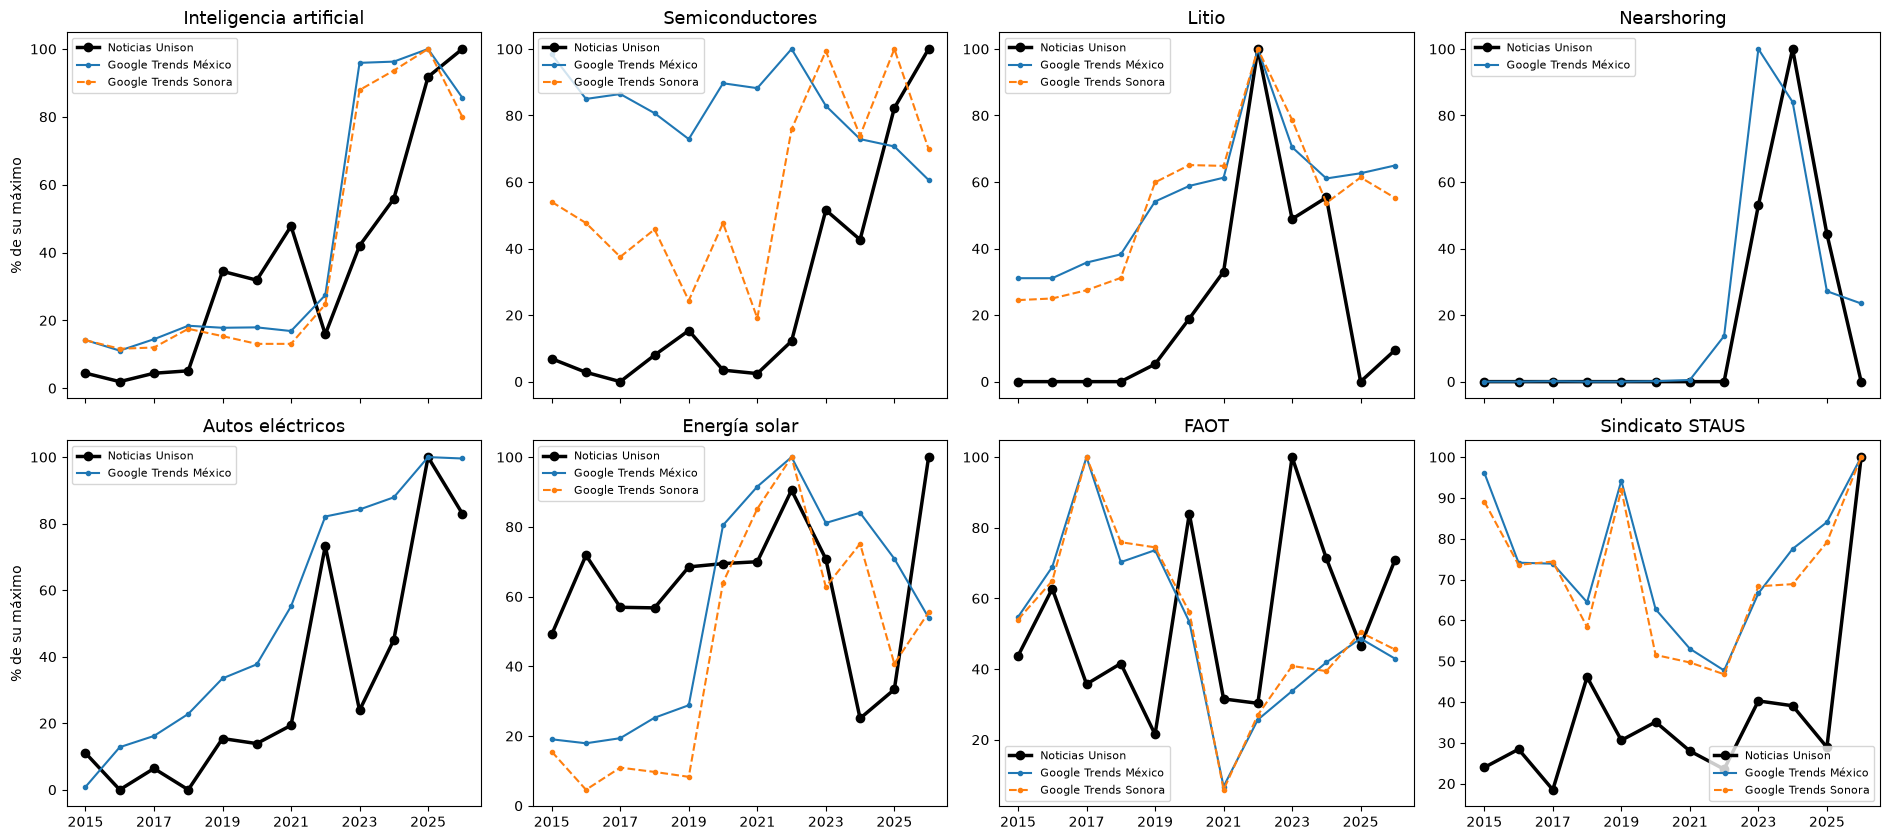

In [6]:
fig, ejes = plt.subplots(2, 4, figsize=(19, 8.5), sharex=True)

for (tema, busqueda), eje in zip(TEMAS.items(), ejes.flatten()):
    unison = unison_por_anio(busqueda["unison"])
    eje.plot(unison.index, unison / unison.max() * 100, marker="o", color="black", linewidth=2.5, label="Noticias Unison")

    for region, estilo in [("México", "-"), ("Sonora", "--")]:
        if hay_datos(busqueda["trends"], region):
            interes = trends_por_anio(busqueda["trends"], region)
            eje.plot(interes.index, interes / interes.max() * 100, estilo, marker=".", label=f"Google Trends {region}")

    eje.set_title(tema, fontsize=13)
    eje.set_xticks(anios[::2])
    eje.legend(fontsize=8)

ejes[0, 0].set_ylabel("% de su máximo")
ejes[1, 0].set_ylabel("% de su máximo")
plt.tight_layout()
plt.show()

## 6. ¿Quién va primero?

Medimos el parecido con la **correlación** (r): 1 si las dos curvas suben y bajan juntas, 0 si no tienen relación y −1 si van
al revés. Además de comparar el mismo año, comparamos la Unison con Trends **del año anterior** (si se parece más, la universidad
va un año atrás del interés del público) y **del año siguiente** (si se parece más, la universidad se adelanta).

Si ninguna de las tres correlaciones llega a **0.5**, decimos que no hay una relación clara.
*Con 12 años de datos, estas correlaciones son una pista, no una prueba.*

In [7]:
def parecido(unison, interes):
    """Correlación de la Unison con Trends del año anterior, del mismo año y del siguiente."""
    return {
        "va atrás (Trends del año anterior)": unison.corr(interes.shift(1)),
        "al mismo tiempo": unison.corr(interes),
        "se adelanta (Trends del año siguiente)": unison.corr(interes.shift(-1)),
    }


filas = []
for tema, busqueda in TEMAS.items():
    unison = unison_por_anio(busqueda["unison"])
    for region in REGIONES:
        if not hay_datos(busqueda["trends"], region):
            continue
        interes = trends_por_anio(busqueda["trends"], region)
        correlaciones = parecido(unison, interes)
        mejor = max(correlaciones, key=correlaciones.get)
        filas.append({
            "tema": tema,
            "región": region,
            "pico Unison": unison.idxmax(),
            "pico Trends": interes.idxmax(),
            "r mismo año": round(correlaciones["al mismo tiempo"], 2),
            "la Unison...": mejor if correlaciones[mejor] >= 0.5 else "sin relación clara",
            "r más alta": round(correlaciones[mejor], 2),
        })

comparacion = pd.DataFrame(filas).set_index(["tema", "región"])
comparacion

pico Unison  pico Trends  r mismo año  \
tema                    región                                          
Inteligencia artificial México         2026         2025         0.79   
                        Sonora         2026         2025         0.78   
Semiconductores         México         2026         2022        -0.76   
                        Sonora         2026         2025         0.70   
Litio                   México         2022         2022         0.84   
                        Sonora         2022         2022         0.79   
Nearshoring             México         2024         2023         0.87   
Autos eléctricos        México         2025         2025         0.86   
Energía solar           México         2026         2022         0.09   
                        Sonora         2026         2022         0.22   
FAOT                    México         2023         2017        -0.18   
                        Sonora         2023         2017        -0.13   
Sindicato STAUS         México         2026         2026         0.41   
                        Sonora         2026         2026         0.43   

                                                      la Unison...  r más alta  
tema                    región                                                  
Inteligencia artificial México  va atrás (Trends del año anterior)        0.87  
                        Sonora  va atrás (Trends del año anterior)        0.87  
Semiconductores         México                  sin relación clara       -0.45  
                        Sonora  va atrás (Trends del año anterior)        0.79  
Litio                   México                     al mismo tiempo        0.84  
                        Sonora                     al mismo tiempo        0.79  
Nearshoring             México                     al mismo tiempo        0.87  
Autos eléctricos        México                     al mismo tiempo        0.86  
Energía solar           México                  sin relación clara        0.30  
                        Sonora                  sin relación clara        0.33  
FAOT                    México                  sin relación clara       -0.18  
                        Sonora                  sin relación clara       -0.13  
Sindicato STAUS         México                  sin relación clara        0.41  
                        Sonora                  sin relación clara        0.43

## 7. Dos casos al mes

### 7.1 Cultura: el FAOT, cada enero

El Festival Alfonso Ortiz Tirado se celebra en Álamos cada enero. Juntamos todos los años y vemos en qué mes del año
se habla y se busca más.

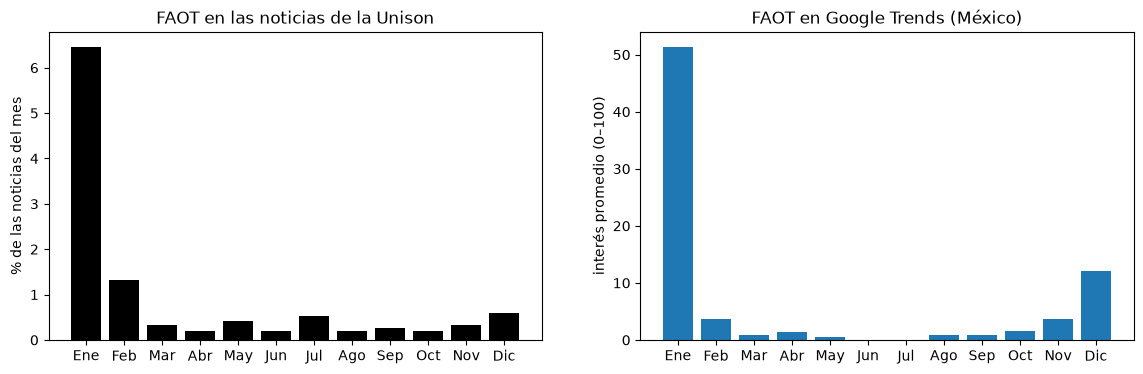

In [8]:
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

faot_unison = noticias["texto"].str.contains(TEMAS["FAOT"]["unison"], case=False)
faot_unison = faot_unison.groupby(noticias["fecha"].dt.month).mean() * 100

faot_trends = serie_trends(TEMAS["FAOT"]["trends"], "México")
faot_trends = faot_trends.groupby(faot_trends.index.month).mean()

fig, (izquierda, derecha) = plt.subplots(1, 2, figsize=(14, 4))
izquierda.bar(nombres_meses, faot_unison.values, color="black")
izquierda.set_title("FAOT en las noticias de la Unison")
izquierda.set_ylabel("% de las noticias del mes")
derecha.bar(nombres_meses, faot_trends.values)
derecha.set_title("FAOT en Google Trends (México)")
derecha.set_ylabel("interés promedio (0–100)")
plt.show()

### 7.2 Vida universitaria: cuando la gente busca al STAUS

El STAUS es el sindicato de académicos de la Unison. Si la gente lo busca en Google, algo está pasando (negociaciones, paros,
huelgas). ¿El portal de la universidad habla del STAUS en esos mismos meses?

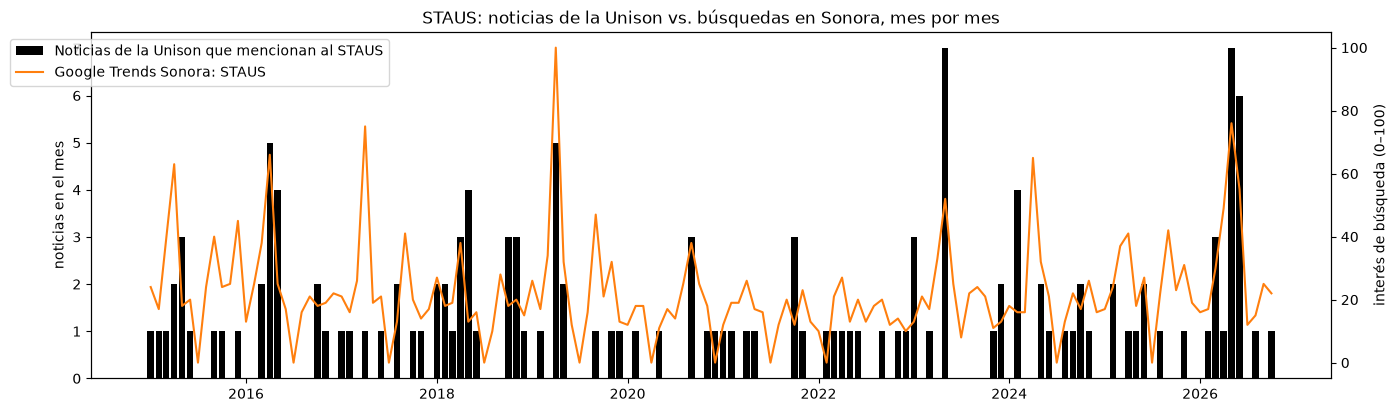

In [9]:
staus_trends = serie_trends(TEMAS["Sindicato STAUS"]["trends"], "Sonora")
staus_unison = noticias["texto"].str.contains(TEMAS["Sindicato STAUS"]["unison"], case=False).groupby(noticias["mes"]).sum()
staus_unison = staus_unison.reindex(staus_trends.index, fill_value=0)

fig, eje = plt.subplots(figsize=(16, 4.5))
eje.bar(staus_unison.index, staus_unison.values, width=25, color="black", label="Noticias de la Unison que mencionan al STAUS")
eje.set_ylabel("noticias en el mes")

eje_trends = eje.twinx()     # segundo eje vertical para Trends
eje_trends.plot(staus_trends.index, staus_trends.values, color="tab:orange", label="Google Trends Sonora: STAUS")
eje_trends.set_ylabel("interés de búsqueda (0–100)")

eje.set_title("STAUS: noticias de la Unison vs. búsquedas en Sonora, mes por mes")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88))
plt.show()

Los 10 meses con más búsquedas del STAUS en Sonora, y cuántas noticias del portal lo mencionaron ese mes:

In [10]:
meses_pico = staus_trends.sort_values(ascending=False).head(10)
pd.DataFrame({
    "interés en Google (0–100)": meses_pico,
    "noticias de la Unison": staus_unison[meses_pico.index],
}).rename_axis("mes").reset_index().assign(mes=lambda tabla: tabla["mes"].dt.strftime("%Y-%m"))

,mes,interés en Google (0–100),noticias de la Unison
0,2019-04,100,5
1,2026-05,76,7
2,2017-04,75,1
3,2016-04,66,5
4,2024-04,65,0
5,2015-04,63,2
6,2026-06,55,6
7,2023-05,52,7
8,2026-04,49,1
9,2019-09,47,1


## 8. Observaciones

### Tecnología: la Unison acompaña, y a veces va un poco atrás

- **Al mismo tiempo que el público:**
  - **Litio:** las tres curvas tienen su pico en **2022** (r = 0.84 con México y 0.79 con Sonora).
    La Unison empieza a hablar del tema en 2019, el mismo año en que suben las búsquedas en Sonora.
  - **Nearshoring** (r = 0.87) y **autos eléctricos** (r = 0.86) suben y bajan con el interés de México.
    El nearshoring tiene su pico de búsquedas en 2023 y en la Unison en 2024.
- **Un año atrás:**
  - **Inteligencia artificial:** el interés del público se dispara en 2023 (probablemente con la llegada de ChatGPT a finales de 2022);
    la Unison sube poco a poco y llega a su máximo en 2026. Se parece más a Trends del año anterior (r = 0.87) que al del mismo año (0.79).
- **Semiconductores: un tema de Sonora, no de México.** En todo México el interés de búsqueda **baja** desde 2015 (r = −0.76: van
  al revés), pero en **Sonora sube** desde 2022, con picos en 2023 y 2025, y la Unison lo sigue (r = 0.70; 0.79 con un año de diferencia).
  Es el ejemplo más claro de que las noticias de la universidad reflejan un tema propio del estado.
- **Energía solar: la universidad ya hablaba antes.** En la Unison es un tema estable desde 2015; el público se interesa hasta 2020–2022.
  Año por año no hay relación (r de 0.1 a 0.3).

### Cultura: el FAOT coincide en el calendario, no en la tendencia

- Año por año no coinciden: las búsquedas del FAOT bajan desde 2017, mientras que en la Unison el festival tiene años altos en 2020 y 2023.
- **Mes por mes, sí:** los dos se concentran en **enero**. Las búsquedas también suben en diciembre (la gente busca antes del festival)
  y la Unison habla de él en enero y febrero (lo cubre durante y después).

### Vida universitaria: el portal cuenta algunos conflictos y otros no

- Las búsquedas del STAUS en Sonora suben **cada abril–mayo**, la temporada de revisión salarial y de contrato
  (los títulos del notebook 03 lo confirman: *"Concretan Unison y Sindicatos negociaciones salariales"*, abril de 2015).
- El portal cubre varios de esos momentos: abril de 2016 (5 notas), abril de 2019 (el mes con más búsquedas: 5 notas),
  mayo de 2023 (7) y mayo–junio de 2026 (13).
- Pero no todos: en **abril de 2024**, uno de los meses con más búsquedas (65 de 100), el portal **no publicó ninguna** nota sobre el STAUS,
  y en abril de 2017 (75 de 100) solo una. Son los casos a revisar en la prensa.

### ¿Responde la pregunta de la historia?

En parte, sí. En tecnología, las noticias de la Unison hablan de los temas que le interesan a la gente de Sonora, al mismo tiempo
(litio, nearshoring, autos eléctricos) o con cerca de un año de retraso (inteligencia artificial, semiconductores). La universidad
**no se adelanta** a los temas nuevos, salvo la energía solar, de la que hablaba desde antes. Y en semiconductores se parece a **Sonora**,
no a México: el tema es local.

### Limitaciones

- Google Trends mide **búsquedas**, no noticias, e incluye búsquedas escolares (eso podría explicar el interés alto de
  *semiconductores* en México en 2015).
- Cada curva tiene su propia escala de 0 a 100 y es una muestra: solo comparamos formas y fechas.
- Buscamos el término exacto; Trends no incluye sinónimos (por ejemplo, *IA* o *vehículos eléctricos*).
- En Sonora no hay datos suficientes para *nearshoring* ni *autos eléctricos*.
- Con 12 años, las correlaciones son una pista, no una prueba; 2026 está incompleto (hasta octubre).

### Siguiente paso (paso 3)

Comparar con **artículos fechados** de uno o dos medios: semiconductores, inteligencia artificial y litio en tecnología,
y los conflictos del STAUS de abril de 2017, abril de 2024 y mayo de 2026.